# 01 · EDA: RetailRocket events

**ทำไมต้องทำ EDA:** ดูข้อมูลก่อนเขียน ETL เพื่อให้ทุกกฎ cleaning และการแบ่งข้อมูลมีตัวเลขรองรับ ไม่ใช่เดา

**วิธีอ่าน notebook นี้:** แต่ละหัวข้อมี 3 ส่วน คือ *ทำอะไร* (คำอธิบายสั้นๆ) → โค้ดพร้อม comment → *สิ่งที่พบ* (ผลที่ได้) สรุปการตัดสินใจรวมอยู่ท้าย notebook

| # | หัวข้อ | ใช้ตัดสินใจเรื่อง |
| --- | --- | --- |
| 1 | คุณภาพข้อมูล | กฎ validate (Pandera) |
| 2 | ช่วงเวลา | วันที่แบ่ง Train / Val / Test |
| 3 | สัดส่วน event | น้ำหนัก event ตอนเทรน ALS |
| 4 | ผู้ใช้และบอท | เกณฑ์ตัดผู้ใช้ผิดปกติ |
| 5 | Session | ขนาด session และ session features |
| 6 | สินค้า (long-tail) | popularity baseline, cold item |
| 7 | Funnel | conversion และ ground truth |
| 8 | Warm / cold | ความยากของโจทย์ใน Val/Test |
| 9 | ไฟล์เสริม | ฟีเจอร์สินค้าและหมวดหมู่ |

## 0. เตรียมข้อมูล
**ทำอะไร:** โหลด `events.csv` แล้วแปลง `timestamp` (epoch มิลลิวินาที) เป็นวันที่-เวลา ไว้ในคอลัมน์ `ts`

In [1]:
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

pl.Config.set_tbl_rows(20)  # แสดงตารางได้สูงสุด 20 แถว
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": 0.3})

RAW = Path("../data/raw")

# timestamp เป็น epoch ms (UTC) -> แปลงเป็น datetime เก็บไว้ที่ ts
events = pl.read_csv(RAW / "events.csv").with_columns(
    pl.from_epoch("timestamp", time_unit="ms").alias("ts")
)
events.head()

timestamp,visitorid,event,itemid,transactionid,ts
i64,i64,str,i64,str,datetime[μs]
1433221332117,257597,"""view""",355908,null,2015-06-02 05:02:12.117
1433224214164,992329,"""view""",248676,null,2015-06-02 05:50:14.164
1433221999827,111016,"""view""",318965,null,2015-06-02 05:13:19.827
1433221955914,483717,"""view""",253185,null,2015-06-02 05:12:35.914
1433221337106,951259,"""view""",367447,null,2015-06-02 05:02:17.106


## 1. คุณภาพข้อมูล
**ทำอะไร:** นับขนาดข้อมูล, หาแถวซ้ำ, หาค่าว่าง และเช็กว่า `transactionid` มีค่าเฉพาะตอน event เป็น `transaction` จริงไหม

**ใช้ทำอะไรต่อ:** ผลตรงนี้กลายเป็นกฎใน Pandera schema ของ ETL

In [2]:
print("rows :", f"{events.height:,}")
print("users:", f"{events['visitorid'].n_unique():,}")
print("items:", f"{events['itemid'].n_unique():,}")

# แถวซ้ำทั้งแถว: extra_copies = จำนวนแถวที่ต้องลบเพื่อให้เหลือชุดเดียว
extra_copies = events.height - events.unique().height
involved = int(events.is_duplicated().sum())  # รวมต้นฉบับที่ถูกซ้ำด้วย
print(f"duplicate rows to remove: {extra_copies} (rows involved in duplicates: {involved})")

print("\nnulls per column:")
events.null_count()

rows : 2,756,101
users: 1,407,580
items: 235,061


duplicate rows to remove: 460 (rows involved in duplicates: 918)

nulls per column:


timestamp,visitorid,event,itemid,transactionid,ts
u32,u32,u32,u32,u32,u32
0,0,0,0,2733644,0


In [3]:
# transactionid ควรมีค่าเฉพาะ event = transaction (ที่เหลือควรว่างทั้งหมด)
events.group_by("event").agg(
    pl.len().alias("rows"),
    pl.col("transactionid").is_not_null().sum().alias("has_transactionid"),
)

event,rows,has_transactionid
str,u32,u32
"""transaction""",22457,22457
"""addtocart""",69332,0
"""view""",2664312,0


**สิ่งที่พบ:** 2.76M events, 1.41M ผู้ใช้, 235K สินค้า มีแถวซ้ำที่ต้องลบ 460 แถว (918 แถวเกี่ยวข้องกับการซ้ำ) `transactionid` ว่างเฉพาะ `view` และ `addtocart` ตามที่ควรเป็น คอลัมน์อื่นไม่มีค่าว่าง

## 2. ช่วงเวลาและวันที่แบ่งข้อมูล
**ทำอะไร:** ดูว่าข้อมูลครอบคลุมช่วงไหน แล้วคำนวณวันแบ่ง Train / Val / Test ตามเวลา (Test = 7 วันสุดท้าย, Val = 7 วันก่อนหน้า)

**ทำไมแบ่งตามเวลา:** ถ้าสุ่มแบ่ง โมเดลจะเห็นอนาคตตอนเทรน (data leakage) ผลที่วัดได้จะสวยเกินจริง

range: 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000 (137 days)


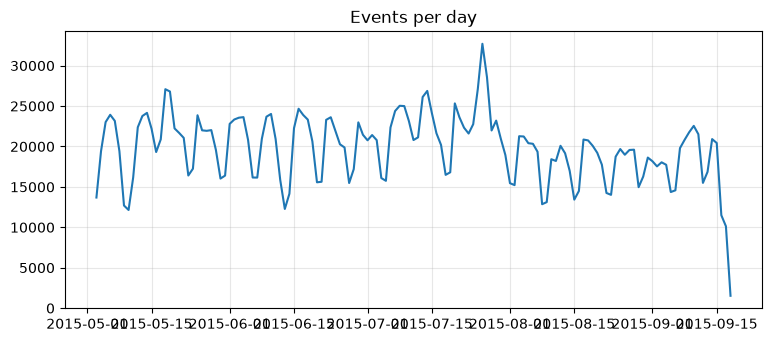

In [4]:
t_min, t_max = events["ts"].min(), events["ts"].max()
print("range:", t_min, "->", t_max, f"({(t_max - t_min).days} days)")

# จำนวน event ต่อวัน ดูว่าสม่ำเสมอหรือมีช่วงแปลก
daily = events.group_by(pl.col("ts").dt.date().alias("day")).agg(pl.len().alias("n")).sort("day")
plt.plot(daily["day"], daily["n"])
plt.title("Events per day")
plt.show()

In [5]:
# กำหนดวันแบ่ง โดยนับย้อนจาก event สุดท้าย
test_start = t_max - timedelta(days=7)
val_start = test_start - timedelta(days=7)
print("val_start :", val_start)
print("test_start:", test_start)

# ติดป้ายว่าแต่ละ event อยู่ชุดไหน (ตัวแปร split ใช้ซ้ำในหัวข้อ 7 และ 8)
split = events.with_columns(
    pl.when(pl.col("ts") >= test_start).then(pl.lit("test"))
    .when(pl.col("ts") >= val_start).then(pl.lit("val"))
    .otherwise(pl.lit("train"))
    .alias("split")
)
split.group_by("split").agg(
    pl.len().alias("events"),
    pl.col("visitorid").n_unique().alias("users"),
    pl.col("ts").min().alias("from"),
    pl.col("ts").max().alias("to"),
).sort("from")

val_start : 2015-09-04 02:59:47.788000
test_start: 2015-09-11 02:59:47.788000


split,events,users,from,to
str,u32,u32,datetime[μs],datetime[μs]
"""train""",2509138,1280329,2015-05-03 03:00:04.384,2015-09-04 02:59:46.763
"""val""",132206,77303,2015-09-04 02:59:55.643,2015-09-11 02:59:45.585
"""test""",114757,67930,2015-09-11 02:59:50.408,2015-09-18 02:59:47.788


**สิ่งที่พบ:** ข้อมูลยาว 137 วัน (3 พ.ค. - 18 ก.ย. 2015) Val เริ่ม 4 ก.ย. และ Test เริ่ม 11 ก.ย. ได้ Train ~2.5M, Val ~132K, Test ~115K events (ก่อนตัดบอท)

## 3. สัดส่วน event
**ทำอะไร:** นับ event แต่ละชนิด และดูว่าสัดส่วนเปลี่ยนไปตามสัปดาห์ไหม

**ใช้ทำอะไรต่อ:** กำหนดน้ำหนักตอนเทรน ALS (ตั้งต้น view = 1, addtocart = 3, transaction = 5)

event,len,pct
str,u32,f64
"""view""",2664312,96.67
"""addtocart""",69332,2.52
"""transaction""",22457,0.81


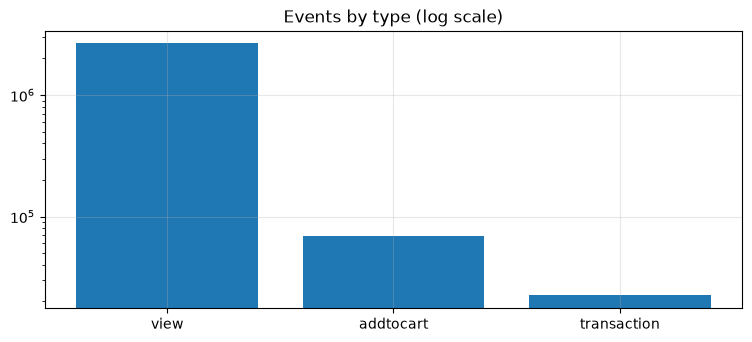

In [6]:
mix = events.group_by("event").len().with_columns(
    (pl.col("len") / events.height * 100).round(2).alias("pct")
).sort("len", descending=True)
display(mix)

# ใช้แกน log เพราะ view มากกว่าอีกสองชนิดหลายสิบเท่า
plt.bar(mix["event"], mix["len"])
plt.yscale("log")
plt.title("Events by type (log scale)")
plt.show()

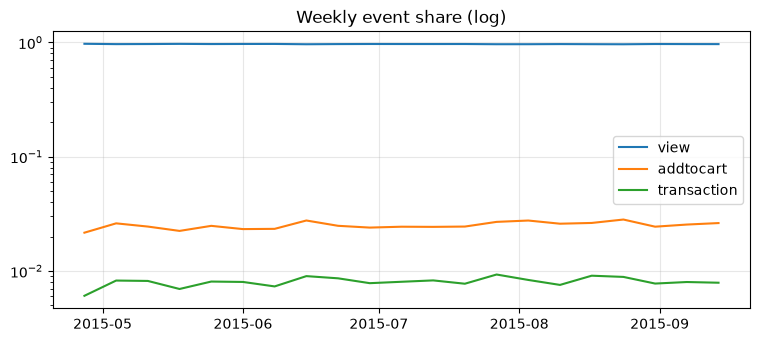

In [7]:
# สัดส่วน event รายสัปดาห์ ถ้าเปลี่ยนมากแปลว่าพฤติกรรมเปลี่ยนตามเวลา (drift)
weekly = (
    events.group_by(pl.col("ts").dt.truncate("1w").alias("week"), "event")
    .len()
    .pivot(on="event", index="week", values="len")
    .sort("week")
    .fill_null(0)
)
week_total = weekly.select(pl.sum_horizontal(pl.exclude("week")))[:, 0]
for e in ["view", "addtocart", "transaction"]:
    plt.plot(weekly["week"], weekly[e] / week_total, label=e)
plt.yscale("log")
plt.legend()
plt.title("Weekly event share (log)")
plt.show()

**สิ่งที่พบ:** view 96.67%, addtocart 2.52%, transaction 0.81% ข้อมูลเอียงไปทาง view มาก จึงต้องให้น้ำหนัก addtocart/transaction สูงกว่า view

## 4. ผู้ใช้และบอท
**ทำอะไร:** นับ event ต่อผู้ใช้ ดูการกระจาย แล้วตรวจกลุ่มที่ event สูงผิดปกติว่าเป็นบอทหรือผู้ใช้จริง

**ใช้ทำอะไรต่อ:** เลือกเกณฑ์ตัดผู้ใช้ผิดปกติใน ETL

In [8]:
# สรุปพฤติกรรมของผู้ใช้แต่ละคน 1 แถวต่อ 1 คน
per_user = events.group_by("visitorid").agg(
    pl.len().alias("n"),                                          # event ทั้งหมด
    (pl.col("event") == "view").sum().alias("views"),
    (pl.col("event") == "addtocart").sum().alias("carts"),
    (pl.col("event") == "transaction").sum().alias("buys"),
    pl.col("itemid").n_unique().alias("items"),                   # จำนวนสินค้าที่ไม่ซ้ำ
    pl.col("ts").min().alias("first"),
    pl.col("ts").max().alias("last"),
)

# percentile ของ event ต่อผู้ใช้
qs = [0.5, 0.9, 0.99, 0.999, 0.9999, 1.0]
pl.DataFrame({"quantile": qs, "events_per_user": [per_user["n"].quantile(q) for q in qs]})

quantile,events_per_user
f64,f64
0.5,1.0
0.9,3.0
0.99,13.0
0.999,47.0
0.9999,279.0
1.0,7757.0


users with exactly 1 event: 71.2%
users with >= 2 events : 28.8%
users with >= 5 events : 5.8%


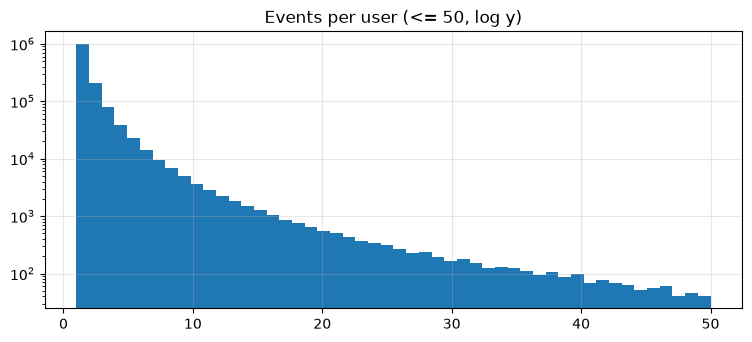

In [9]:
print(f"users with exactly 1 event: {(per_user['n'] == 1).mean():.1%}")
print(f"users with >= 2 events : {(per_user['n'] >= 2).mean():.1%}")
print(f"users with >= 5 events : {(per_user['n'] >= 5).mean():.1%}")

# กราฟเฉพาะผู้ใช้ที่มี <= 50 events (ส่วนที่เหลือยาวเกินไป) ใช้แกน y แบบ log
plt.hist(per_user.filter(pl.col("n") <= 50)["n"], bins=50)
plt.yscale("log")
plt.title("Events per user (<= 50, log y)")
plt.show()

In [10]:
# ถ้าตัดผู้ใช้ที่เกินแต่ละ percentile จะเสียผู้ใช้และ events เท่าไร
total = events.height
rows = []
for q in [0.99, 0.999, 0.9999]:
    thr = per_user["n"].quantile(q)
    top = per_user.filter(pl.col("n") > thr)
    rows.append({
        "cutoff": f"p{q * 100:g}",
        "threshold": thr,
        "users_removed": top.height,
        "events_removed": top["n"].sum(),
        "pct_events": round(top["n"].sum() / total * 100, 2),
    })
pl.DataFrame(rows)

cutoff,threshold,users_removed,events_removed,pct_events
str,f64,i64,i64,f64
"""p99""",13.0,12712,465283,16.88
"""p99.9""",47.0,1352,219927,7.98
"""p99.99""",279.0,141,117944,4.28


In [11]:
# ผู้ใช้ที่มี event มากที่สุด 15 คน
per_user.sort("n", descending=True).head(15)

visitorid,n,views,carts,buys,items,first,last
i64,u32,u32,u32,u32,u32,datetime[μs],datetime[μs]
1150086,7757,6479,719,559,3814,2015-06-11 14:55:17.389,2015-09-17 02:57:11.237
530559,4328,3623,419,286,2209,2015-06-15 18:59:25.103,2015-09-17 02:14:14.827
152963,3024,2304,371,349,1622,2015-07-31 21:14:28.499,2015-09-18 02:48:46.605
895999,2474,2368,56,50,1641,2015-05-06 15:10:32.815,2015-09-18 02:41:59.083
163561,2410,2194,124,92,1314,2015-05-03 18:08:45.953,2015-06-04 02:57:16.915
371606,2345,2141,110,94,1399,2015-06-25 19:13:49.090,2015-07-19 21:24:06.548
286616,2252,2057,120,75,1230,2015-05-09 15:27:36.222,2015-06-07 02:33:59.412
684514,2246,1826,231,189,1187,2015-05-31 18:41:23.341,2015-07-06 20:16:21.983
892013,2024,2023,1,0,1738,2015-07-03 22:30:43.524,2015-08-31 21:02:29.748


In [12]:
# กลุ่ม "heavy" = เกิน p99.9 ดูว่าเหมือนบอทไหม (บอทมักดูอย่างเดียว ไม่ซื้อ)
p999 = per_user["n"].quantile(0.999)
heavy = per_user.filter(pl.col("n") > p999).with_columns(
    ((pl.col("last") - pl.col("first")).dt.total_hours() + 1).alias("hours_active"),
).with_columns((pl.col("n") / pl.col("hours_active")).alias("events_per_hour"))

print("heavy users:", heavy.height, "| with any purchase:", (heavy["buys"] > 0).sum())
heavy.select(["n", "views", "carts", "buys", "items", "hours_active", "events_per_hour"]).describe()

heavy users: 1352 | with any purchase: 506


statistic,n,views,carts,buys,items,hours_active,events_per_hour
str,f64,f64,f64,f64,f64,f64,f64
"""count""",1352.0,1352.0,1352.0,1352.0,1352.0,1352.0,1352.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",162.667899,146.342456,10.715237,5.610207,88.723373,1074.52071,2.250461
"""std""",364.514257,315.549396,34.459293,25.6569,208.174752,997.265949,8.178605
"""min""",48.0,0.0,0.0,0.0,1.0,1.0,0.015443
"""25%""",56.0,52.0,0.0,0.0,22.0,215.0,0.050926
"""50%""",72.0,66.0,1.0,0.0,36.0,732.0,0.128713
"""75%""",117.0,111.0,8.0,2.0,65.0,1800.0,0.532895
"""max""",7757.0,6479.0,719.0,559.0,3814.0,3312.0,133.0


In [13]:
# เทียบอัตรา cart/buy ของ heavy กับผู้ใช้ทั่วไป
normal = per_user.filter(pl.col("n") <= p999)
for name, d in [("normal", normal), ("heavy", heavy)]:
    buy_rate = d["buys"].sum() / d["n"].sum()
    cart_rate = d["carts"].sum() / d["n"].sum()
    print(f"{name:7s} users={d.height:>9,} buy_rate={buy_rate:.4%} cart_rate={cart_rate:.4%}")

normal  users=1,406,228 buy_rate=0.5864% cart_rate=2.1625%
heavy   users=    1,352 buy_rate=3.4489% cart_rate=6.5872%


**สิ่งที่พบ:** ผู้ใช้ 71.2% มี event เดียว (มัธยฐาน = 1, p99.9 = 47, สูงสุด 7,757) กลุ่ม heavy ซื้อมากกว่าผู้ใช้ทั่วไปถึง ~6 เท่า (3.45% เทียบกับ 0.59%) และ 506 จาก 1,352 คนมีการซื้อ จึง **ไม่ใช่บอทชัดเจน** การตัดที่ p99.9 ตรงๆ จะทิ้งผู้ซื้อตัวจริงและเสีย 8% ของ events ทางเลือกที่ใช้ใน ETL คือตัดเฉพาะคนที่ event สูงแต่ไม่เคย cart/ซื้อ ร่วมกับเพดานที่ p99.99

## 5. Session
**ทำอะไร:** แบ่ง event ของผู้ใช้แต่ละคนเป็น session ถ้าห่างกันเกิน 30 นาทีถือว่าเริ่ม session ใหม่ แล้วดูความยาวและโอกาสซื้อ

**ใช้ทำอะไรต่อ:** ตัดสินใจว่าควรทำ session features ไหม (ใช้กับ user ใหม่ที่ไม่มีประวัติ)

In [14]:
GAP = pl.duration(minutes=30)

ev = (
    events.sort(["visitorid", "ts"])
    # เวลาห่างจาก event ก่อนหน้าของผู้ใช้คนเดียวกัน
    .with_columns(pl.col("ts").diff().over("visitorid").alias("gap"))
    # event แรกของผู้ใช้ หรือห่างเกิน 30 นาที = เริ่ม session ใหม่
    .with_columns((pl.col("gap").is_null() | (pl.col("gap") > GAP)).cast(pl.Int32).alias("new"))
    # สะสมจำนวนจุดเริ่ม = เลข session ของผู้ใช้คนนั้น
    .with_columns(pl.col("new").cum_sum().over("visitorid").alias("session"))
)

# สรุป 1 แถวต่อ 1 session
sessions = ev.group_by(["visitorid", "session"]).agg(
    pl.len().alias("n"),
    (pl.col("ts").max() - pl.col("ts").min()).dt.total_seconds().alias("dur_s"),
    (pl.col("event") == "addtocart").any().alias("cart"),
    (pl.col("event") == "transaction").any().alias("buy"),
)
print("sessions:", f"{sessions.height:,}", "| per user (mean):", round(sessions.height / per_user.height, 2))

qs = [0.5, 0.75, 0.9, 0.99, 0.999]
pl.DataFrame({
    "quantile": qs,
    "events_per_session": [sessions["n"].quantile(q) for q in qs],
    "duration_min": [round(sessions["dur_s"].quantile(q) / 60, 1) for q in qs],
})

sessions: 1,761,675 | per user (mean): 1.25


quantile,events_per_session,duration_min
f64,f64,f64
0.5,1.0,0.0
0.75,1.0,0.0
0.9,2.0,3.5
0.99,9.0,29.9
0.999,30.0,89.1


single-event sessions: 78.3%


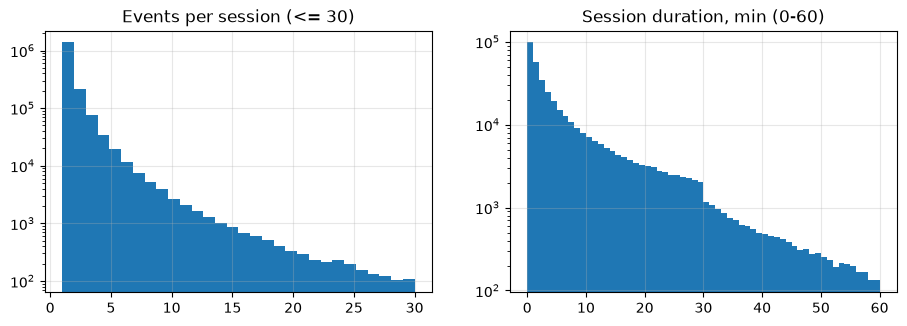

In [15]:
print(f"single-event sessions: {(sessions['n'] == 1).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(sessions.filter(pl.col("n") <= 30)["n"], bins=30)
ax[0].set_yscale("log")
ax[0].set_title("Events per session (<= 30)")

# ตัด session ที่ระยะเวลา 0 วินาที (มี event เดียว) ออกจากกราฟระยะเวลา
long_enough = sessions.filter((pl.col("dur_s") > 0) & (pl.col("dur_s") <= 3600))
ax[1].hist(long_enough["dur_s"] / 60, bins=60)
ax[1].set_yscale("log")
ax[1].set_title("Session duration, min (0-60)")
plt.show()

In [16]:
# session ยาวขึ้น มีโอกาส cart/buy มากขึ้นไหม (จัดกลุ่ม 10 = 10 events ขึ้นไป)
(
    sessions.with_columns(pl.col("n").clip(upper_bound=10).alias("len_bucket"))
    .group_by("len_bucket")
    .agg(
        pl.len().alias("sessions"),
        pl.col("cart").mean().round(4).alias("p_cart"),
        pl.col("buy").mean().round(4).alias("p_buy"),
    )
    .sort("len_bucket")
)

len_bucket,sessions,p_cart,p_buy
u32,u32,f64,f64
1,1378895,0.0027,0.0004
2,210714,0.047,0.0066
3,74548,0.116,0.0441
4,34129,0.1604,0.0631
5,19248,0.1815,0.0703
6,11823,0.2099,0.0848
7,7531,0.233,0.0902
8,5278,0.2499,0.093
9,3926,0.2672,0.1052


**สิ่งที่พบ:** 1.76M sessions (เฉลี่ย 1.25 ต่อคน) และ 78.3% มี event เดียว ความยาว session ทำนายการซื้อได้ชัด: session 1 event ซื้อ 0.04%, 3 events 4.4%, 10 events ขึ้นไป 19.2% จึงควรใช้ความยาว session เป็นฟีเจอร์ใน Ranker

## 6. สินค้า (long-tail)
**ทำอะไร:** ดูว่าความนิยมของสินค้ากระจุกตัวแค่ไหน และถ้าตัดผู้ใช้/สินค้าที่มี event น้อยออก (เพื่อเทรน ALS) จะเหลือข้อมูลเท่าไร

**ใช้ทำอะไรต่อ:** ประเมินความแข็งแรงของ popularity baseline และกำหนด event ขั้นต่ำของ ALS

In [17]:
per_item = events.group_by("itemid").agg(
    pl.len().alias("n"),
    (pl.col("event") == "transaction").sum().alias("buys"),
    pl.col("visitorid").n_unique().alias("users"),
).sort("n", descending=True)

print("items:", f"{per_item.height:,}", "| median events/item:", per_item["n"].median())
for pct in [0.01, 0.05, 0.2]:
    k = int(per_item.height * pct)
    share = per_item.head(k)["n"].sum() / events.height
    print(f"top {pct:.0%} items ({k:,}) = {share:.1%} of events")
print(f"items with <= 5 events: {(per_item['n'] <= 5).mean():.1%}")

items: 235,061 | median events/item: 3.0
top 1% items (2,350) = 22.9% of events
top 5% items (11,753) = 49.3% of events
top 20% items (47,012) = 78.7% of events
items with <= 5 events: 65.8%


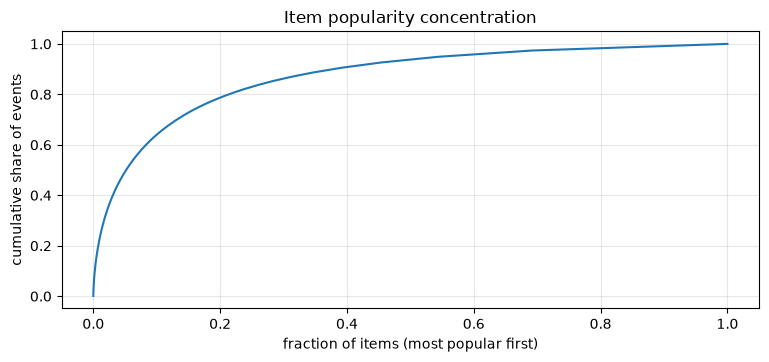

In [18]:
# กราฟสะสม: สินค้ายอดนิยมกี่ % ครอบคลุม events กี่ %
cum = per_item["n"].cum_sum() / events.height
plt.plot([i / per_item.height for i in range(per_item.height)], cum)
plt.xlabel("fraction of items (most popular first)")
plt.ylabel("cumulative share of events")
plt.title("Item popularity concentration")
plt.show()

In [19]:
# สินค้ายอดนิยม 10 อันดับแรก
per_item.head(10)

itemid,n,buys,users
i64,u32,u32,u32
187946,3412,0,2912
461686,2978,133,1393
5411,2334,0,2079
370653,1854,0,1577
219512,1800,12,1370
257040,1647,27,986
298009,1642,0,1342
96924,1633,0,1359
309778,1628,15,1055


In [20]:
# ถ้า ALS ใช้เฉพาะผู้ใช้/สินค้าที่มี event ขั้นต่ำ m ครั้ง จะเหลือข้อมูลเท่าไร
rows = []
for m in [1, 2, 3, 5]:
    u = per_user.filter(pl.col("n") >= m)["visitorid"]
    i = per_item.filter(pl.col("n") >= m)["itemid"]
    kept = events.filter(pl.col("visitorid").is_in(u.implode()) & pl.col("itemid").is_in(i.implode()))
    rows.append({
        "min_events": m,
        "users": u.len(),
        "items": i.len(),
        "events_kept": kept.height,
        "pct_events": round(kept.height / events.height * 100, 1),
    })
pl.DataFrame(rows)

min_events,users,items,events_kept,pct_events
i64,i64,i64,i64,f64
1,1407580,235061,2756101,100.0
2,406020,161452,1726175,62.6
3,200028,126623,1303009,47.3
5,81620,90948,897028,32.5


**สิ่งที่พบ:** สินค้า top 1% คิดเป็น 22.9% ของ events และ top 20% คิดเป็น 78.7% ขณะที่ 65.8% ของสินค้ามี event ไม่เกิน 5 ครั้ง ผลคือ popularity baseline จะแข็งและเอาชนะยาก ถ้าตั้ง event ขั้นต่ำของ ALS ที่ 2 จะเหลือผู้ใช้ 406K คนและ 62.6% ของ events

## 7. Funnel และ ground truth
**ทำอะไร:** ดูว่าผู้ใช้เดินจาก view → addtocart → ซื้อ ได้กี่ % และนับผู้ใช้ที่มี ground truth ในแต่ละช่วง

**Ground truth** = สินค้าที่ผู้ใช้ใส่ตะกร้าหรือซื้อในช่วงนั้น ใช้เป็นคำตอบถูกตอนวัด Recall / NDCG

In [21]:
u_view = per_user.filter(pl.col("views") > 0).height
u_cart = per_user.filter(pl.col("carts") > 0).height
u_buy = per_user.filter(pl.col("buys") > 0).height
print(f"users view -> cart -> buy: {u_view:,} -> {u_cart:,} ({u_cart / u_view:.1%}) -> {u_buy:,} ({u_buy / u_view:.1%})")

# ผู้ซื้อกี่ % เคยใส่ตะกร้ามาก่อน
bought_and_carted = per_user.filter((pl.col("buys") > 0) & (pl.col("carts") > 0)).height
print(f"buyers that also have addtocart: {bought_and_carted / u_buy:.1%}")
print(f"unique transactions: {events['transactionid'].n_unique():,}")

users view -> cart -> buy: 1,404,179 -> 37,722 (2.7%) -> 11,719 (0.8%)
buyers that also have addtocart: 90.2%
unique transactions: 17,673


In [22]:
# ผู้ใช้ที่มี ground truth (addtocart หรือ transaction) ในแต่ละชุด
gt = split.filter(pl.col("event") != "view")
gt.group_by("split").agg(
    pl.col("visitorid").n_unique().alias("users_with_gt"),
    pl.len().alias("gt_events"),
).sort("split")

split,users_with_gt,gt_events
str,u32,u32
"""test""",1750,3869
"""train""",35401,83614
"""val""",1961,4306


**สิ่งที่พบ:** ผู้ใช้ 2.7% ใส่ตะกร้า และ 0.8% ซื้อ (90% ของผู้ซื้อเคยใส่ตะกร้ามาก่อน) Val มีผู้ใช้ที่มี ground truth แค่ 1,961 คน และ Test 1,750 คน จำนวนน้อย metrics จะแกว่งง่าย

## 8. Warm vs cold (ความยากของโจทย์)
**ทำอะไร:** ดูว่าผู้ใช้และสินค้าใน Val/Test เคยปรากฏใน Train หรือไม่

- **Warm user** = เคยอยู่ใน Train, ALS มีข้อมูลของเขา
- **Cold user** = ไม่เคยเห็น, ต้องพึ่ง session หรือสินค้า popular

In [23]:
train = split.filter(pl.col("split") == "train")
train_users = set(train["visitorid"].unique().to_list())
train_items = set(train["itemid"].unique().to_list())

rows = []
for s in ["val", "test"]:
    g = gt.filter(pl.col("split") == s)
    users = g["visitorid"].unique().to_list()
    items = g["itemid"].unique().to_list()
    rows.append({
        "split": s,
        "gt_users": len(users),
        "warm_users_pct": round(sum(u in train_users for u in users) / len(users) * 100, 1),
        "gt_items": len(items),
        "seen_items_pct": round(sum(i in train_items for i in items) / len(items) * 100, 1),
    })
pl.DataFrame(rows)

split,gt_users,warm_users_pct,gt_items,seen_items_pct
str,i64,f64,i64,f64
"""val""",1961,15.7,2424,94.0
"""test""",1750,13.8,2209,95.4


**สิ่งที่พบ:** ผู้ใช้ใน Val/Test เป็น warm เพียง **15.7% / 13.8%** ที่เหลือเป็น cold แต่สินค้า 94-95% เคยเห็นใน Train แปลว่าปัญหาหลักคือ *ผู้ใช้ใหม่* ไม่ใช่สินค้าใหม่ จึงต้องรายงานผล warm / cold แยกกัน

## 9. ไฟล์เสริม
**ทำอะไร:** ดูโครงสร้าง `category_tree.csv` และ `item_properties_part1.csv` (ไฟล์ใหญ่ ~460 MB อ่านแบบ lazy เพื่อไม่กินแรม)

**ใช้ทำอะไรต่อ:** เลือก property ที่จะใช้ทำฟีเจอร์สินค้า (ตั้งใจใช้ `categoryid` กับ `available`)

In [24]:
cat = pl.read_csv(RAW / "category_tree.csv")
print("categories:", cat.height, "| roots:", cat["parentid"].is_null().sum())
cat.head()

categories: 1669 | roots: 25


categoryid,parentid
i64,i64
1016,213
809,169
570,9
1691,885
536,1691


In [25]:
# อ่านทุกคอลัมน์เป็น string (infer_schema=False) เพราะ value มีหลายชนิดปนกัน
props = pl.scan_csv(RAW / "item_properties_part1.csv", infer_schema=False)

# property ที่พบบ่อยที่สุด 12 อันดับ
props.group_by("property").len().sort("len", descending=True).head(12).collect()

property,len
str,u32
"""888""",1629817
"""790""",970800
"""available""",817387
"""categoryid""",426305
"""6""",343207
"""283""",323681
"""776""",311654
"""678""",261829
"""364""",256340


In [26]:
# ตรวจ 2 property ที่ตั้งใจใช้: มีกี่แถว ครอบคลุมกี่สินค้า มีกี่ค่าที่ไม่ซ้ำ
for p in ["categoryid", "available"]:
    stats = props.filter(pl.col("property") == p).select(
        pl.len().alias("rows"),
        pl.col("itemid").n_unique().alias("items"),
        pl.col("value").n_unique().alias("distinct_values"),
    ).collect()
    print(p, stats.to_dicts())

categoryid [{'rows': 426305, 'items': 229341, 'distinct_values': 1196}]
available [{'rows': 817387, 'items': 236884, 'distinct_values': 2}]


**สิ่งที่พบ:** `categoryid` ครอบคลุม 229,341 สินค้า (1,196 หมวด) และ `available` มี 2 ค่า (ใช่/ไม่ใช่) ส่วน property อื่นเป็นรหัสตัวเลขที่ไม่รู้ความหมาย จึงข้ามไป

## สรุปผล EDA และการตัดสินใจสำหรับ ETL

| หัวข้อ | ที่พบ | การตัดสินใจ |
| --- | --- | --- |
| ขนาด | 2,756,101 events, 1,407,580 users, 235,061 items, 137 วัน (3 พ.ค. - 18 ก.ย. 2015) | ใช้ Polars บนเครื่องส่วนตัวได้สบาย |
| ข้อมูลซ้ำ | 460 แถวที่ต้องลบ (918 แถวเกี่ยวข้องกับการซ้ำ) | ลบทิ้งใน ETL |
| Schema | `transactionid` มีค่าเฉพาะ `transaction` (22,457 แถว) ไม่มี null ในคอลัมน์อื่น | Pandera: บังคับว่า `transactionid` ต้องไม่ว่างเมื่อเป็น `transaction` เท่านั้น |
| สัดส่วน event | view 96.67%, addtocart 2.52%, transaction 0.81% | ตั้งต้นน้ำหนัก ALS ตามแผน (1 / 3 / 5) แล้วจูน |
| การแบ่งข้อมูล | Val เริ่ม 2015-09-04, Test เริ่ม 2015-09-11 (ตามเวลา UTC ของ timestamp) | Train 2.51M, Val 132K, Test 115K events |
| ผู้ใช้ | 71.2% มี event เดียว, มัธยฐาน 1, p99.9 = 47, สูงสุด 7,757 | ALS ใช้เฉพาะ user ที่มี >= 2 events (เหลือ 406K users, 62.6% ของ events) |
| ผู้ใช้ event สูง | ไม่ใช่บอทชัดเจน: กลุ่ม > p99.9 ซื้อสินค้า 3.45% ของ event (ผู้ใช้ทั่วไป 0.59%) และ 506 จาก 1,352 คนมีการซื้อ | ดูหมายเหตุด้านล่าง |
| Session (ห่าง 30 นาที) | 1.76M sessions, 78.3% มี event เดียว | session features ใช้ได้เฉพาะ ~22% ของ session |
| สัญญาณจาก session | session 1 event: P(buy) = 0.04%, 3 events = 4.4%, 10+ events = 19.2% | ความยาว session เป็นฟีเจอร์ที่ได้ผลแน่ ใช้ใน Ranker |
| สินค้า | top 1% = 22.9% ของ events, top 20% = 78.7%, 65.8% มี <= 5 events | popularity baseline จะแข็งแรง เป็นเส้นเทียบที่เอาชนะยาก |
| Ground truth | Val 1,961 users, Test 1,750 users (addtocart/transaction) | จำนวนน้อย metrics จะแกว่ง ควรรายงานช่วงความเชื่อมั่น |
| **Warm vs cold** | ผู้ใช้ใน Val/Test ที่เคยอยู่ใน Train มีแค่ **15.7% / 13.8%** | ส่วนใหญ่เป็น cold user ต้องรายงาน warm / cold แยกกัน และ fallback เป็นสินค้า popular + session สำคัญมาก |
| สินค้าใน Val/Test | 94.0% / 95.4% เคยเห็นใน Train | ปัญหาสินค้าใหม่ไม่รุนแรง |
| ไฟล์เสริม | `categoryid` มี 229,341 สินค้า, `available` มี 2 ค่า, category tree 1,669 หมวด | ใช้ 2 property นี้เท่านั้น ข้ามที่เหลือ |

### ข้อสังเกตที่ต้องตัดสินใจก่อนเขียน ETL

1. **เกณฑ์ตัดบอท**: แผนเสนอ p99.9 (47 events) แต่กลุ่มนั้นซื้อบ่อยกว่าปกติ และตัดแล้วเสีย 8% ของ events ข้อมูลไม่ได้บอกว่าเป็นบอท ทางเลือกคือ (ก) ใช้ p99.99 อย่างเดียว (279 events, ตัด 141 คน, 4.3% ของ events) หรือ (ข) ตัดเฉพาะคนที่ event สูงแต่ไม่เคย addtocart/transaction เลย **ETL ใช้ (ข) ร่วมกับเพดาน p99.99** ผลคือตัด 651 คน (159,845 events) และปรับได้ที่ `BotFilter` ใน `src/etl/config.py`
2. **Warm user น้อย**: ผลของ ALS จะวัดได้กับผู้ใช้แค่ ~15% ที่เหลือพึ่ง popular และ session features ตั้งแต่ต้องออกแบบ evaluation ให้แยก warm / cold
3. **วันที่แบ่ง**: เวลาในไฟล์เป็น epoch ms ตีความเป็น UTC ตลอดทั้งโปรเจกต์ เพื่อไม่ให้ขอบเขต Val/Test ขยับ